# Embedding pipeline

This notebook traces what `BWEmbedder` does to a raw `(C, T)` neural signal before it reaches the Whisper encoder, following the actual pipeline order.

**Sections**
1. Environment & imports
2. Load data & build embedder
3. Month/Day projection — inter-session alignment
4. Convolutional pipeline
5. Day encoding
6. Positional encoding (BWEncoder)
7. Patch embeddings — full pipeline output

---
## 1. Environment & imports

In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import sys
import re

REPO_ROOT = os.path.abspath(os.path.join(os.path.dirname('__file__'), '..'))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

_envrc = os.path.join(REPO_ROOT, ".envrc")
if os.path.exists(_envrc):
    with open(_envrc) as _f:
        for _line in _f:
            _m = re.match(r'^export\s+(\w+)=(["\']?)(.+?)\2\s*$', _line.strip())
            if _m:
                _key, _val = _m.group(1), _m.group(3)
                if _key not in os.environ:
                    os.environ[_key] = _val
                    print(f"  set  {_key} = {_val}")
                else:
                    print(f"  skip {_key}  (already in environment)")
else:
    print(f"WARNING: .envrc not found at {_envrc}")

import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import display, Image as IPyImage
from transformers import WhisperTokenizer

from brainwhisperer.viz import load_theme
THEME = load_theme()

TOKENIZER = WhisperTokenizer.from_pretrained(
    'openai/whisper-tiny', language='en', task='transcribe'
)

os.makedirs('outputs', exist_ok=True)

print('torch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

  skip CARD_ROOT  (already in environment)
  skip KUNZ_ROOT  (already in environment)
  skip WILLETT_ROOT  (already in environment)
  skip RNN_ARGS  (already in environment)
torch 2.11.0+cu128
CUDA available: True


---
## 2. Load data & build embedder

Load one batch and instantiate `BWEmbedder`. Forward hooks on `conv1` and `conv2` capture raw activations at each stage for the visualisations below.

In [3]:
from brainwhisperer.data.collate import NeuralCollator
from brainwhisperer.data.registry import get_dataset
from brainwhisperer.data.batch import NeuralBatch
from torch.utils.data import DataLoader

BATCH_SIZE = 8
COLLATOR   = NeuralCollator(TOKENIZER)

ds     = None
loader = None

for dataset_name in ('card', 'willet'):
    try:
        if dataset_name == 'card':
            import brainwhisperer.data.datasets.card   # noqa
        else:
            import brainwhisperer.data.datasets.willett  # noqa
        ds     = get_dataset(dataset_name)(split='train')
        loader = DataLoader(ds, batch_size=BATCH_SIZE, collate_fn=COLLATOR, shuffle=True)
        print(f'Loaded {dataset_name!r} — {len(ds)} samples')
        break
    except Exception as exc:
        print(f'{dataset_name}: {exc}')

if ds is not None:
    batch  = next(iter(loader))
    n_days = int(ds._base.days.max().item()) + 1
else:
    print('No real dataset — using synthetic fallback')
    n_days = 20
    B, C, T_max = 8, 512, 3000
    lengths = torch.randint(800, T_max, (B,))
    signals = torch.zeros(B, C, T_max)
    for i, L in enumerate(lengths):
        signals[i, :, :L] = torch.randn(C, L.item())
    batch = NeuralBatch(
        signals=signals, labels=torch.randint(0, 200, (B, 10)),
        sbj_idx=torch.zeros(B, dtype=torch.long),
        day_idx=torch.randint(0, n_days, (B,)), lengths=lengths,
    )

print('signals:', tuple(batch.signals.shape))

Loaded 'card' — 8069 samples
signals: (8, 512, 1265)


In [13]:
# ── parameters ────────────────────────────────────────────────────────────────
EMBED_SAMPLE_IDX = 0
# ──────────────────────────────────────────────────────────────────────────────

from brainwhisperer.config.schema import BWEmbedderConfig
from brainwhisperer.models.embedder import BWEmbedder

_cfg = BWEmbedderConfig(
    num_features    = 512,
    d_model         = 384,
    embed_type      = 'conv',
    kernel_size_1   = 7,
    stride_2        = 2,
    patch_size      = 5,
    encodings       = 'sin',
    day_projections = True,
    day_proj_rank   = 16,
    dropout         = 0.4,
)
_embedder = BWEmbedder(_cfg, num_days=n_days).eval()

_acts: dict = {}
def _hook(name):
    def _fn(module, inp, out): _acts[name] = out.detach()
    return _fn

_embedder.conv1.register_forward_hook(_hook('conv1'))
_embedder.conv2.register_forward_hook(_hook('conv2'))

_sig = batch.signals[[EMBED_SAMPLE_IDX]].float()
with torch.no_grad():
    _embedder(_sig, batch.day_idx[[EMBED_SAMPLE_IDX]])

# GELU is fused inside _embed_conv; apply here to match actual downstream activations
_signal_np  = _sig[0].cpu().numpy()                   # (C, T)
_act_conv1  = F.gelu(_acts['conv1'])[0].cpu().numpy() # (d_model, T)
_act_conv2  = F.gelu(_acts['conv2'])[0].cpu().numpy() # (d_model, 1500)

print(f'Input  : {_signal_np.shape}')
print(f'Conv1  : {_act_conv1.shape}')
print(f'Conv2  : {_act_conv2.shape}')

Input  : (512, 1265)
Conv1  : (384, 3000)
Conv2  : (384, 1500)


---
## 3. Month/Day projection: inter-session alignment

The **first** operation in the pipeline. Each raw temporal frame $x_t \in \mathbb{R}^C$ is passed through a per-session affine map:

$$\tilde{x}_t = \sigma\!\left((W_{mth} + A_{day}B_{day})\,x_t + b_{mth} + b_{day}\right)$$

$W_{mth} \in \mathbb{R}^{C \times C}$ corrects for slow drift shared across a ~30-day block; the low-rank product $A_{day}B_{day}$ handles residual within-month variation. These corrected frames are the ones fed into the convolutional layers.

The PCA below visualises the effect: each point is the mean of all sampled frames from one recording session (45 sessions, one per day). 
Within-session variance is collapsed so the plot shows only between-session drift. PCA reveals how the projection pulls these session centroids toward a common location.

*Set `CKPT_PATH` to a trained checkpoint to see the effect on real data; `None` uses a synthetic demonstration.*

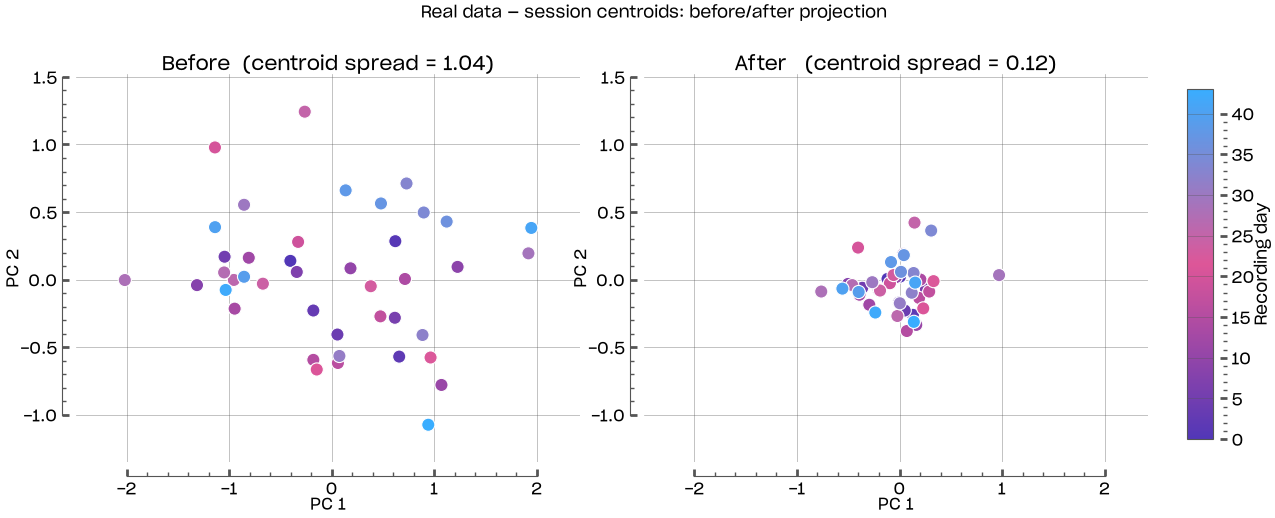

In [14]:
import glob
import pickle
import sys

from brainwhisperer.viz.embeddings import plot_session_centroids_pca
from brainwhisperer.config.paths import CARD_ROOT

# ── parameters ────────────────────────────────────────────────────────────────
_ORIG_ROOT    = "/home/francesco/evo-exp-brain-to-voice-online/whisper-based"
_CKPT_GLOB    = f"{_ORIG_ROOT}/ckpts/*.ckpt"
_PREFIX       = "model.embedders.0."
N_FRAMES_PLOT = 60     # frames sampled per day for the scatter
N_PCA_DIMS    = 2      # 2 or 3
N_DAYS_DEMO   = 8      # synthetic only
N_MONTHS_DEMO = 2      # synthetic only
N_FRAMES_DAY  = 80     # synthetic only
# ──────────────────────────────────────────────────────────────────────────────

_ckpts = sorted(glob.glob(_CKPT_GLOB))

if _ckpts:
    # ── Real weights ──────────────────────────────────────────────────────────
    sd = torch.load(_ckpts[-1], map_location='cpu', weights_only=False)['state_dict']

    # reconstruct session_to_month: sparse original month indices → contiguous
    _days_tensor    = sd[_PREFIX + 'sessions_to_days.session_to_idx_map']   # (45,)
    _orig_months    = (_days_tensor // 30).long().tolist()
    _unique_months  = sorted(set(_orig_months))
    _remap          = {m: i for i, m in enumerate(_unique_months)}
    _s2m_contiguous = [_remap[m] for m in _orig_months]

    _n_days = sum(1 for k in sd if k.startswith(_PREFIX + 'day_As.'))
    _C      = sd[_PREFIX + 'day_As.0'].shape[0]
    _r      = sd[_PREFIX + 'day_As.0'].shape[1]

    _cfg_real = BWEmbedderConfig(
        num_features=_C, d_model=384, embed_type='conv',
        kernel_size_1=7, stride_2=2, patch_size=5,
        encodings='sin', day_projections=True, day_proj_rank=_r, dropout=0.0,
    )
    _emb_real = BWEmbedder(_cfg_real, num_days=_n_days, session_to_month=_s2m_contiguous)

    with torch.no_grad():
        _emb_real.proj_W_month.copy_(torch.stack(
            [sd[f'{_PREFIX}month_weights.{m}'] for m in _unique_months]))
        _emb_real.proj_b_month.copy_(torch.stack(
            [sd[f'{_PREFIX}month_biases.{m}'].squeeze(0) for m in _unique_months]))
        _emb_real.proj_A.copy_(torch.stack(
            [sd[f'{_PREFIX}day_As.{d}'] for d in range(_n_days)]))
        _emb_real.proj_B.copy_(torch.stack(
            [sd[f'{_PREFIX}day_Bs.{d}'] for d in range(_n_days)]))
        _emb_real.proj_b_day.copy_(torch.stack(
            [sd[f'{_PREFIX}day_biases.{d}'].squeeze(0) for d in range(_n_days)]))
    _emb_real.eval()

    # load real data from CARD pickle
    if CARD_ROOT not in sys.path:
        sys.path.insert(0, CARD_ROOT)
    from model_training.augmented_dataset import BaseNeuralTextDataset
    with open(f'{CARD_ROOT}/data/cleaned_train_data.pkl', 'rb') as _f:
        _raw = pickle.load(_f)
    _ds_real = BaseNeuralTextDataset(_raw, eval_type='val', source_dataset='card')

    _step    = max(1, len(_ds_real) // 64)
    _items   = [_ds_real[i * _step] for i in range(64)]
    _rng_r   = np.random.default_rng(0)
    frames_list, labels_list = [], []
    for item in _items:
        feat = item['neural_features']   # (T, C)
        T_i  = feat.shape[0]
        d    = int(item['day'].item())
        idx  = _rng_r.choice(T_i, size=min(N_FRAMES_PLOT, T_i), replace=False)
        frames_list.append(feat[idx].numpy())
        labels_list.extend([d] * len(idx))

    frames     = np.vstack(frames_list)
    day_labels = np.array(labels_list)

    with torch.no_grad():
        _x_bct = torch.from_numpy(frames).float().unsqueeze(0).permute(0, 2, 1)  # (1, C, N)
        _proj  = _emb_real._apply_day_proj(
            _x_bct, torch.from_numpy(day_labels).long()
        )                                                                          # (1, C, N)
    frames_proj = _proj[0].permute(1, 0).numpy()                                  # (N, C)

    title_prefix = 'Real data'

else:
    # ── Synthetic fallback ────────────────────────────────────────────────────
    rng   = np.random.default_rng(42)
    C_raw = 512
    days_per_month = N_DAYS_DEMO // N_MONTHS_DEMO
    day_to_month   = [d // days_per_month for d in range(N_DAYS_DEMO)]

    month_offsets = rng.standard_normal((N_MONTHS_DEMO, C_raw)) * 5.0
    day_offsets   = rng.standard_normal((N_DAYS_DEMO, C_raw))   * 1.5

    frames_list, labels_list = [], []
    for d in range(N_DAYS_DEMO):
        content = rng.standard_normal((N_FRAMES_DAY, C_raw))
        drift   = month_offsets[day_to_month[d]] + day_offsets[d]
        frames_list.append(content + drift)
        labels_list.extend([d] * N_FRAMES_DAY)

    frames     = np.vstack(frames_list)
    day_labels = np.array(labels_list)

    frames_proj = frames.copy()
    for d in range(N_DAYS_DEMO):
        mask = day_labels == d
        frames_proj[mask] -= frames_proj[mask].mean(axis=0)

    title_prefix = 'Synthetic'

with THEME:
        fig = plot_session_centroids_pca(
            frames, 
            frames_proj, 
            day_labels, 
            title_prefix
        )
display(fig)

---
## 4. Convolutional pipeline

After projection the signal is padded or trimmed to a fixed `T = 3000` time steps, then mapped to `(d_model=384, 1500)` tokens via two `torch.nn.Conv1d` layers followed by `GELU`.

**`Conv1d` mechanics (PyTorch notation).**  
A `Conv1d(in_channels, out_channels, kernel_size)` holds a weight tensor of shape `(C_out, C_in, K)` and a bias of shape `(C_out,)`. For an input of shape `(N, C_in, T_in)`, the output at batch index `n`, output channel `j`, and time step `t` is:

$$\text{out}[n,\, j,\, t] = \text{bias}[j] + \sum_{k=0}^{K-1} \sum_{i=0}^{C_{in}-1} \text{weight}[j,\, i,\, k] \cdot \text{input}[n,\, i,\, t \cdot s + k]$$

The three indices `[n, j, t]` are: **batch sample**, **output channel**, **time step**.  
`weight[j]` is one filter of shape `(C_in, K)` which is element-wise multiplied with the corresponding `(C_in, K)` input patch and summed, yielding **one scalar**. 
Repeating for all `C_out` filters at every position `t` fills the full output `(N, C_out, T_out)`.

Since BrainWhisperer uses an embedding dimension of 384, convolutions are implemented setting `C_out = 384`. The number of output filters sets the output channel dimension directly — no pooling, no compression across channels.

---

**First convolution**:`Conv1d(in_channels=512, out_channels=384, kernel_size=7, padding=3, stride=1)`  
`padding = kernel_size // 2 = 3` is "same" padding: $T_{out} = T_{in}$.  
Each output position aggregates 7 consecutive input frames across all 512 electrode channels.

$$512 \times 3000 \xrightarrow{\text{Conv1 + GELU}} 384 \times 3000$$

**Second convolution**: `Conv1d(in_channels=384, out_channels=384, kernel_size=3, padding=1, stride=2)`  
`stride=2` halves the time axis:

$$T_{out} = \left\lfloor \frac{T_{in} + 2p - K}{s} \right\rfloor + 1 = \left\lfloor \frac{3000 + 2 - 3}{2} \right\rfloor + 1 = 1500$$

$$384 \times 3000 \xrightarrow{\text{Conv2 + GELU}} 384 \times 1500$$

**Tokens.** Each column of the `(384, 1500)` output is one token fed to the BrainWhisperer encoder. The 1500-token length matches BrainWhisperer's expected input.

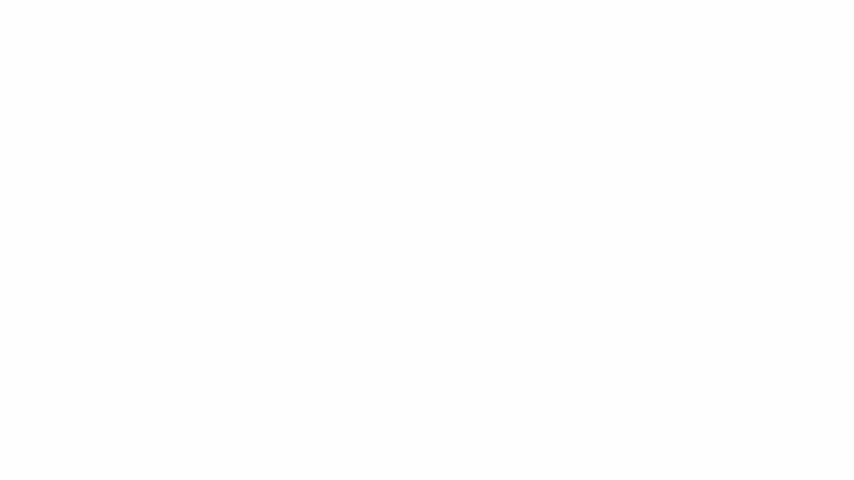

In [20]:
from brainwhisperer.viz.animations import render_conv1_mechanics_gif

_gif_path = 'outputs/conv1_mechanics.gif'
if not os.path.exists(_gif_path):
    render_conv1_mechanics_gif(
        _signal_np, _gif_path,
        C=_cfg.num_features, Dm=_cfg.d_model, K1=_cfg.kernel_size_1,
    )
display(IPyImage(_gif_path))

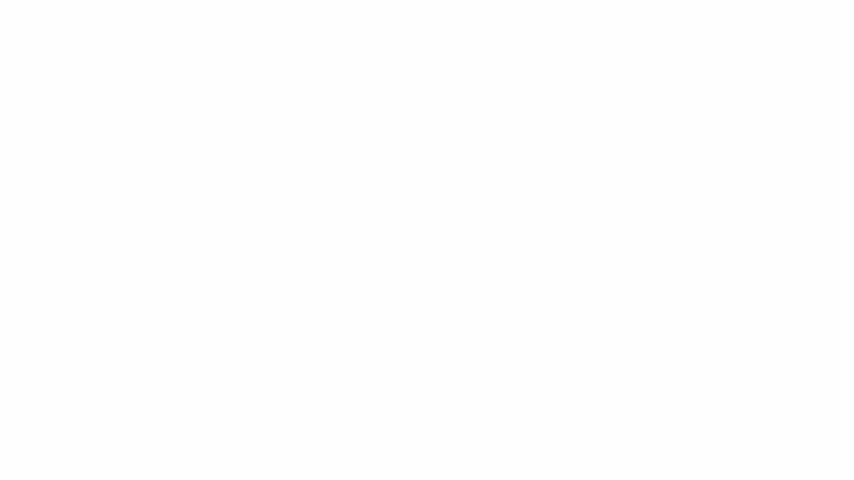

In [21]:
from brainwhisperer.viz.animations import render_conv1_sliding_gif

_gif_path = 'outputs/conv1_sliding.gif'
if not os.path.exists(_gif_path):
    render_conv1_sliding_gif(
        _signal_np, _act_conv1, _gif_path,
        C=_cfg.num_features, Dm=_cfg.d_model, K1=_cfg.kernel_size_1,
    )
display(IPyImage(_gif_path))

---
## 5. Day encoding

After the conv layers, `BWEmbedder` adds a sinusoidal **day encoding** to the right half of each token's feature vector, injecting session identity into every position of the sequence. The heatmap shows the encoding vectors for a range of recording days.

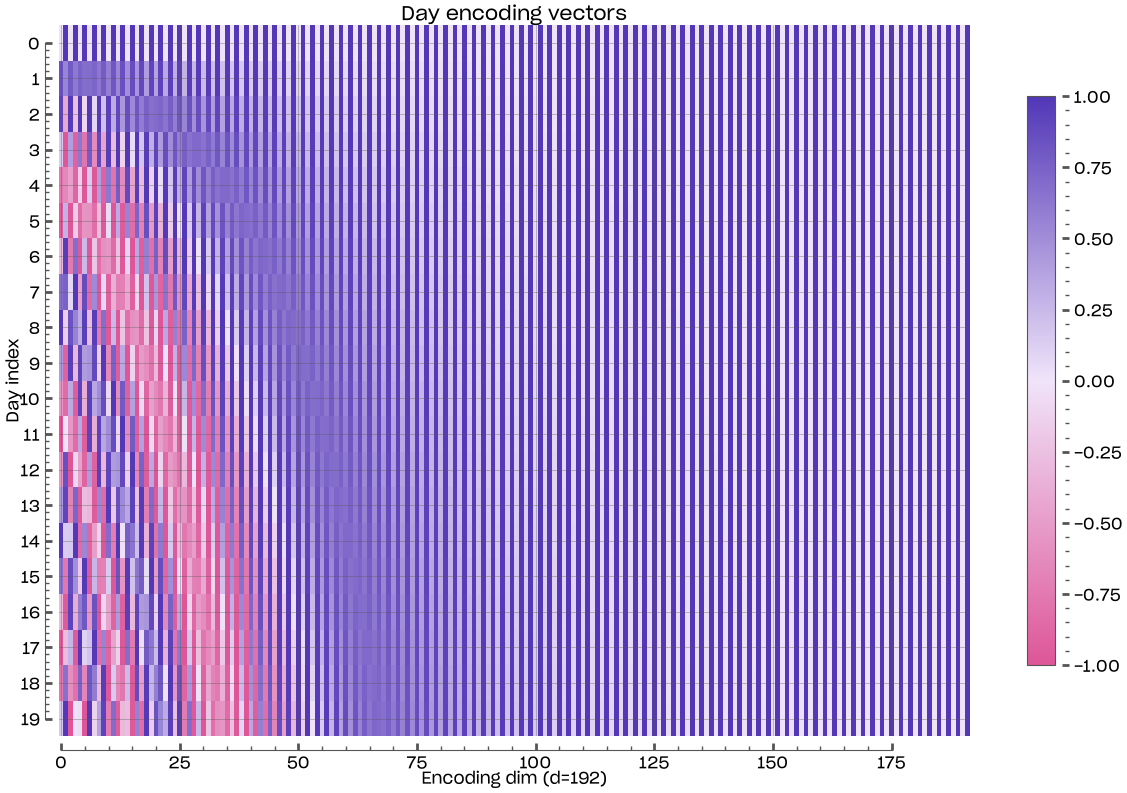

In [25]:
from brainwhisperer.viz.embeddings import plot_day_encoding

# ── parameters ────────────────────────────────────────────────────────────────
N_DAYS_TO_SHOW = min(n_days, 20)
# ──────────────────────────────────────────────────────────────────────────────

with THEME:
    fig = plot_day_encoding(_embedder, torch.arange(N_DAYS_TO_SHOW))
display(fig)

---
## 6. Positional encoding (BWEncoder)

The first operation inside `BWEncoder` adds a sinusoidal **sequence-position** encoding to the right half of each token — the same half used by the day encoding above. This injects token-position information (0 to 1499) so the transformer attention layers can distinguish early from late time steps.

Note: this is distinct from the day encoding. Both are additive into the same `d_model//2` dimensions, meaning they accumulate before the first transformer layer.

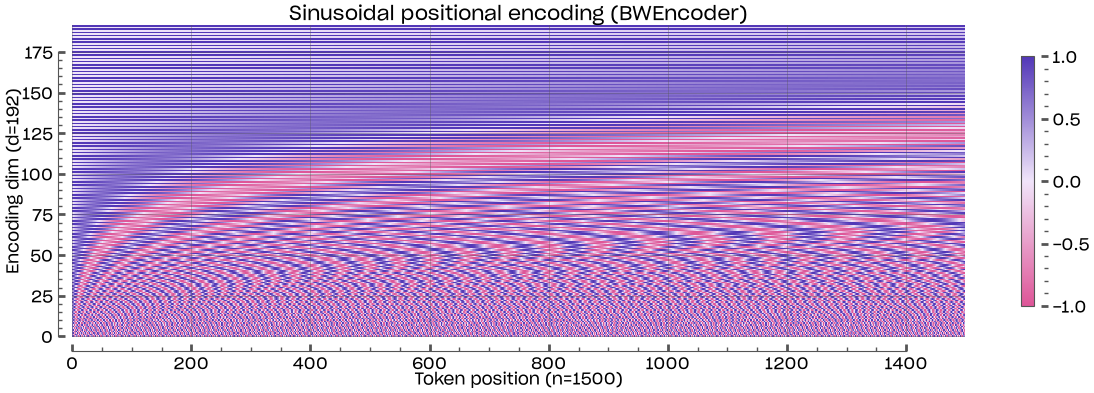

In [24]:
from brainwhisperer.viz.embeddings import plot_positional_encoding

with THEME:
    fig = plot_positional_encoding(n_tokens=1500, d_model=_cfg.d_model)
display(fig)

---
## 7. Patch embeddings — full pipeline output

The full embedder output after all transforms: `(B, 1500, d_model)`. Each row is one token passed to the Whisper encoder.

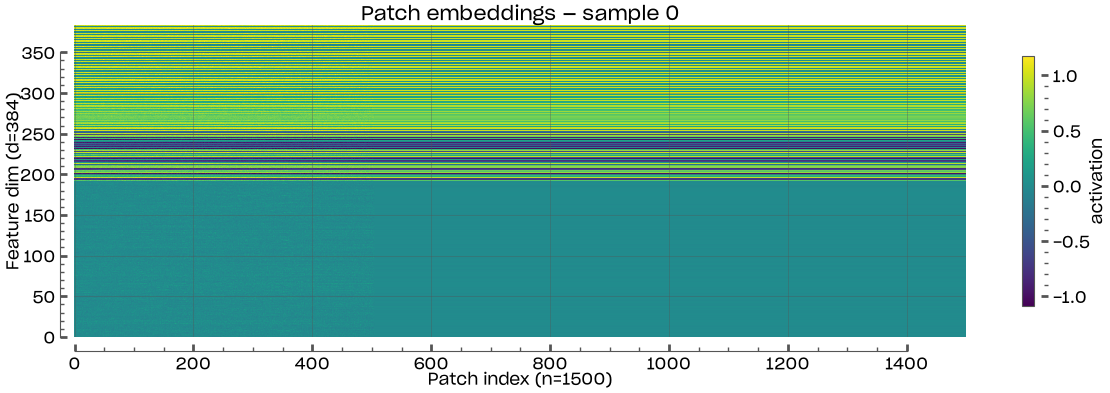

In [26]:
from brainwhisperer.viz.embeddings import plot_patch_embeddings

with torch.no_grad():
    _embeddings = _embedder(batch.signals.float(), batch.day_idx)   # (B, 1500, d_model)

with THEME:
    fig = plot_patch_embeddings(_embeddings, sample_idx=EMBED_SAMPLE_IDX)
display(fig)